Matplotlib Session 12 – Mini Case Study

In [1]:

# MATPLOTLIB SESSION 12 - TASK 1
# College Fest Registration Dataset
# Fictional dataset for KPI dashboard analysis

import numpy as np
import pandas as pd
from pathlib import Path

# Reproducible random data
np.random.seed(42)

# Business configuration
TOTAL_REGISTRATIONS = 600

START_DATE = "2026-01-05"
END_DATE = "2026-02-18"

EVENTS = [
    "Dance",
    "Music",
    "Coding",
    "Quiz",
    "Gaming"
]

# Generate registration dates
date_range = pd.date_range(
    start=START_DATE,
    end=END_DATE,
    freq="D"
)

registration_dates = np.random.choice(
    date_range,
    size=TOTAL_REGISTRATIONS
)

# Event selection with realistic popularity differences
events = np.random.choice(
    EVENTS,
    size=TOTAL_REGISTRATIONS,
    p=[0.25, 0.28, 0.20, 0.12, 0.15]
)

# Ticket categories
ticket_types = np.random.choice(
    ["Student", "Guest"],
    size=TOTAL_REGISTRATIONS,
    p=[0.80, 0.20]
)

# Ticket pricing
ticket_prices = np.where(
    ticket_types == "Student",
    150,
    300
)

# Participant ages
ages = np.random.randint(
    17,
    26,
    size=TOTAL_REGISTRATIONS
)

# Create DataFrame
df = pd.DataFrame({
    "reg_date": pd.to_datetime(registration_dates),
    "event": events,
    "ticket_type": ticket_types,
    "ticket_price_inr": ticket_prices,
    "age": ages
})

# Sort registrations chronologically
df = df.sort_values(
    by="reg_date"
).reset_index(drop=True)

# Validate dataset
assert len(df) == 600
assert df["reg_date"].between(
    START_DATE, END_DATE
).all()

assert df["age"].between(17, 25).all()

assert (
    df.loc[df["ticket_type"] == "Student", "ticket_price_inr"]
    == 150
).all()

assert (
    df.loc[df["ticket_type"] == "Guest", "ticket_price_inr"]
    == 300
).all()

# Save CSV
output_file = Path("fest_registrations.csv")

df.to_csv(
    output_file,
    index=False,
    date_format="%Y-%m-%d"
)

# Print summary
print("=" * 55)
print("COLLEGE FEST REGISTRATION DATASET")
print("=" * 55)

print("\nTotal Registrations:", len(df))

print(
    "Registration Period:",
    df["reg_date"].min().date(),
    "to",
    df["reg_date"].max().date()
)

print(
    "Total Revenue: ₹",
    f"{df['ticket_price_inr'].sum():,}"
)

print("\nEvent-wise Registrations:")
print(df["event"].value_counts())

print("\nTicket Type Distribution:")
print(df["ticket_type"].value_counts())

print("\nFirst 10 Records:")
print(df.head(10).to_string(index=False))

print("\nDataset Shape:", df.shape)

print("\nSaved Successfully:", output_file.resolve())

print("\nSESSION 12 - TASK 1 COMPLETED!")


COLLEGE FEST REGISTRATION DATASET

Total Registrations: 600
Registration Period: 2026-01-05 to 2026-02-18
Total Revenue: ₹ 107,550

Event-wise Registrations:
event
Music     168
Coding    136
Dance     132
Quiz       87
Gaming     77
Name: count, dtype: int64

Ticket Type Distribution:
ticket_type
Student    483
Guest      117
Name: count, dtype: int64

First 10 Records:
  reg_date  event ticket_type  ticket_price_inr  age
2026-01-05   Quiz     Student               150   23
2026-01-05 Gaming     Student               150   19
2026-01-05 Coding     Student               150   25
2026-01-05 Coding     Student               150   17
2026-01-05 Coding     Student               150   18
2026-01-05 Gaming       Guest               300   25
2026-01-05   Quiz     Student               150   17
2026-01-05  Dance     Student               150   23
2026-01-05  Dance       Guest               300   23
2026-01-05  Dance       Guest               300   18

Dataset Shape: (600, 5)

Saved Successfull

Task 2: Create a Professional 2×2 KPI Dashboard

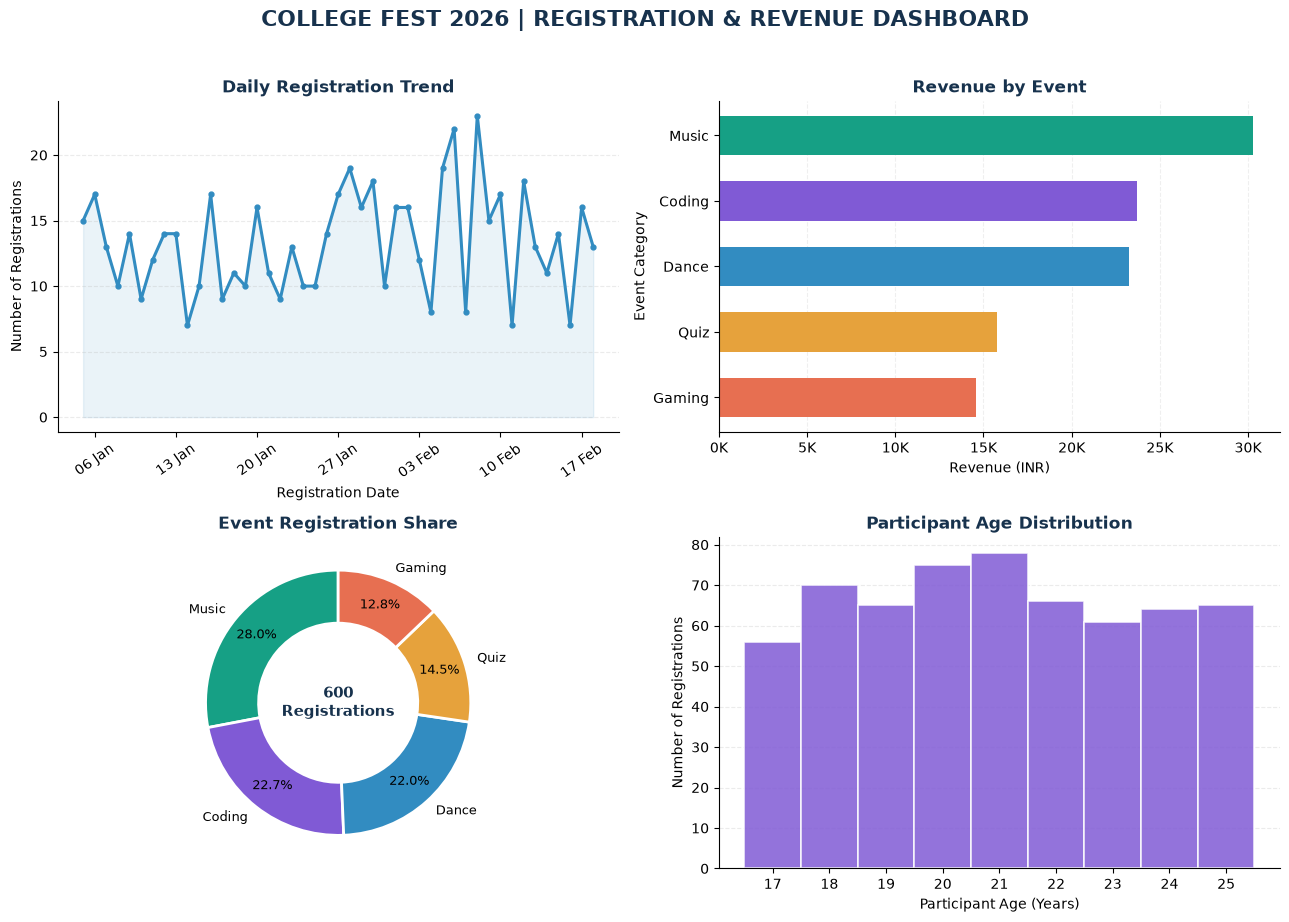

COLLEGE FEST 2026 - KPI PERFORMANCE SUMMARY
Total Registrations : 600
Total Revenue       : INR 107,550.00
Average Ticket Price: INR 179.25

Event-wise Revenue:
event
Gaming    14550
Quiz      15750
Dance     23250
Coding    23700
Music     30300

SESSION 12 - TASK 2 COMPLETED SUCCESSFULLY!


In [2]:

# ============================================================
# MATPLOTLIB SESSION 12 - TASK 2
# COLLEGE FEST PERFORMANCE KPI DASHBOARD
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from pathlib import Path

# ------------------------------------------------------------
# 1. LOAD AND VALIDATE DATASET
# ------------------------------------------------------------

file_path = Path("fest_registrations.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "fest_registrations.csv not found. "
        "Check your notebook working directory."
    )

df = pd.read_csv(
    file_path,
    parse_dates=["reg_date"]
)

required_columns = {
    "reg_date",
    "event",
    "ticket_type",
    "ticket_price_inr",
    "age"
}

missing = required_columns - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

# ------------------------------------------------------------
# 2. PREPARE BUSINESS METRICS
# ------------------------------------------------------------

# Daily registration counts
daily_registrations = (
    df.groupby("reg_date")
    .size()
    .reindex(
        pd.date_range(
            df["reg_date"].min(),
            df["reg_date"].max(),
            freq="D"
        ),
        fill_value=0
    )
)

# Revenue by event
event_revenue = (
    df.groupby("event")["ticket_price_inr"]
    .sum()
    .sort_values(ascending=True)
)

# Event-wise registration counts
event_counts = (
    df["event"]
    .value_counts()
    .sort_values(ascending=False)
)

# Overall KPIs
total_registrations = len(df)
total_revenue = df["ticket_price_inr"].sum()
average_ticket_price = df["ticket_price_inr"].mean()

# ------------------------------------------------------------
# 3. DEFINE PROFESSIONAL COLORS
# ------------------------------------------------------------

NAVY = "#17324D"
BLUE = "#328CC1"
GREEN = "#16A085"
ORANGE = "#E6A23C"
PURPLE = "#805AD5"

event_colors = {
    "Dance": "#328CC1",
    "Music": "#16A085",
    "Coding": "#805AD5",
    "Quiz": "#E6A23C",
    "Gaming": "#E76F51"
}

# ------------------------------------------------------------
# 4. CREATE 2 x 2 KPI DASHBOARD
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 9)
)

ax1, ax2 = axes[0]
ax3, ax4 = axes[1]

# ------------------------------------------------------------
# CHART 1 - DAILY REGISTRATION TREND
# ------------------------------------------------------------

ax1.plot(
    daily_registrations.index,
    daily_registrations.values,
    color=BLUE,
    linewidth=2.2,
    marker="o",
    markersize=3.5
)

ax1.fill_between(
    daily_registrations.index,
    daily_registrations.values,
    color=BLUE,
    alpha=0.10
)

ax1.set_title(
    "Daily Registration Trend",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

ax1.set_xlabel("Registration Date")
ax1.set_ylabel("Number of Registrations")

ax1.xaxis.set_major_locator(
    mdates.WeekdayLocator(interval=1)
)

ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

ax1.tick_params(
    axis="x",
    rotation=35
)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

# ------------------------------------------------------------
# CHART 2 - REVENUE BY EVENT
# ------------------------------------------------------------

bar_colors = [
    event_colors[event]
    for event in event_revenue.index
]

ax2.barh(
    event_revenue.index,
    event_revenue.values,
    color=bar_colors,
    height=0.6
)

ax2.set_title(
    "Revenue by Event",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

ax2.set_xlabel("Revenue (INR)")
ax2.set_ylabel("Event Category")

ax2.xaxis.set_major_formatter(
    FuncFormatter(
        lambda value, pos: f"{value / 1000:,.0f}K"
    )
)

ax2.grid(
    axis="x",
    linestyle="--",
    alpha=0.20
)

ax2.set_axisbelow(True)

# ------------------------------------------------------------
# CHART 3 - EVENT REGISTRATION SHARE
# ------------------------------------------------------------

donut_colors = [
    event_colors[event]
    for event in event_counts.index
]

ax3.pie(
    event_counts.values,
    labels=event_counts.index,
    colors=donut_colors,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.80,
    wedgeprops=dict(
        width=0.4,
        edgecolor="white",
        linewidth=2
    ),
    textprops=dict(fontsize=9)
)

# Add centre label
ax3.text(
    0,
    0,
    f"{total_registrations:,}\nRegistrations",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color=NAVY
)

ax3.set_title(
    "Event Registration Share",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

ax3.set_aspect("equal")

# ------------------------------------------------------------
# CHART 4 - PARTICIPANT AGE DISTRIBUTION
# ------------------------------------------------------------

age_bins = np.arange(16.5, 26.5, 1)

ax4.hist(
    df["age"],
    bins=age_bins,
    color=PURPLE,
    edgecolor="white",
    linewidth=1.2,
    alpha=0.85
)

ax4.set_title(
    "Participant Age Distribution",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

ax4.set_xlabel("Participant Age (Years)")
ax4.set_ylabel("Number of Registrations")

ax4.set_xticks(range(17, 26))

ax4.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax4.set_axisbelow(True)

# ------------------------------------------------------------
# 5. APPLY CONSISTENT DASHBOARD FORMATTING
# ------------------------------------------------------------

for ax in [ax1, ax2, ax4]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Overall dashboard title
fig.suptitle(
    "COLLEGE FEST 2026 | REGISTRATION & REVENUE DASHBOARD",
    fontsize=16,
    fontweight="bold",
    color=NAVY,
    y=1.02
)

# Required by assignment
fig.tight_layout()

# Display dashboard
plt.show()

# ------------------------------------------------------------
# 6. PRINT BUSINESS KPI SUMMARY
# ------------------------------------------------------------

print("=" * 55)
print("COLLEGE FEST 2026 - KPI PERFORMANCE SUMMARY")
print("=" * 55)

print(f"Total Registrations : {total_registrations:,}")
print(f"Total Revenue       : INR {total_revenue:,.2f}")
print(f"Average Ticket Price: INR {average_ticket_price:,.2f}")

print("\nEvent-wise Revenue:")
print(event_revenue.to_string())

print("\nSESSION 12 - TASK 2 COMPLETED SUCCESSFULLY!")


Task 3: Add KPI Annotations

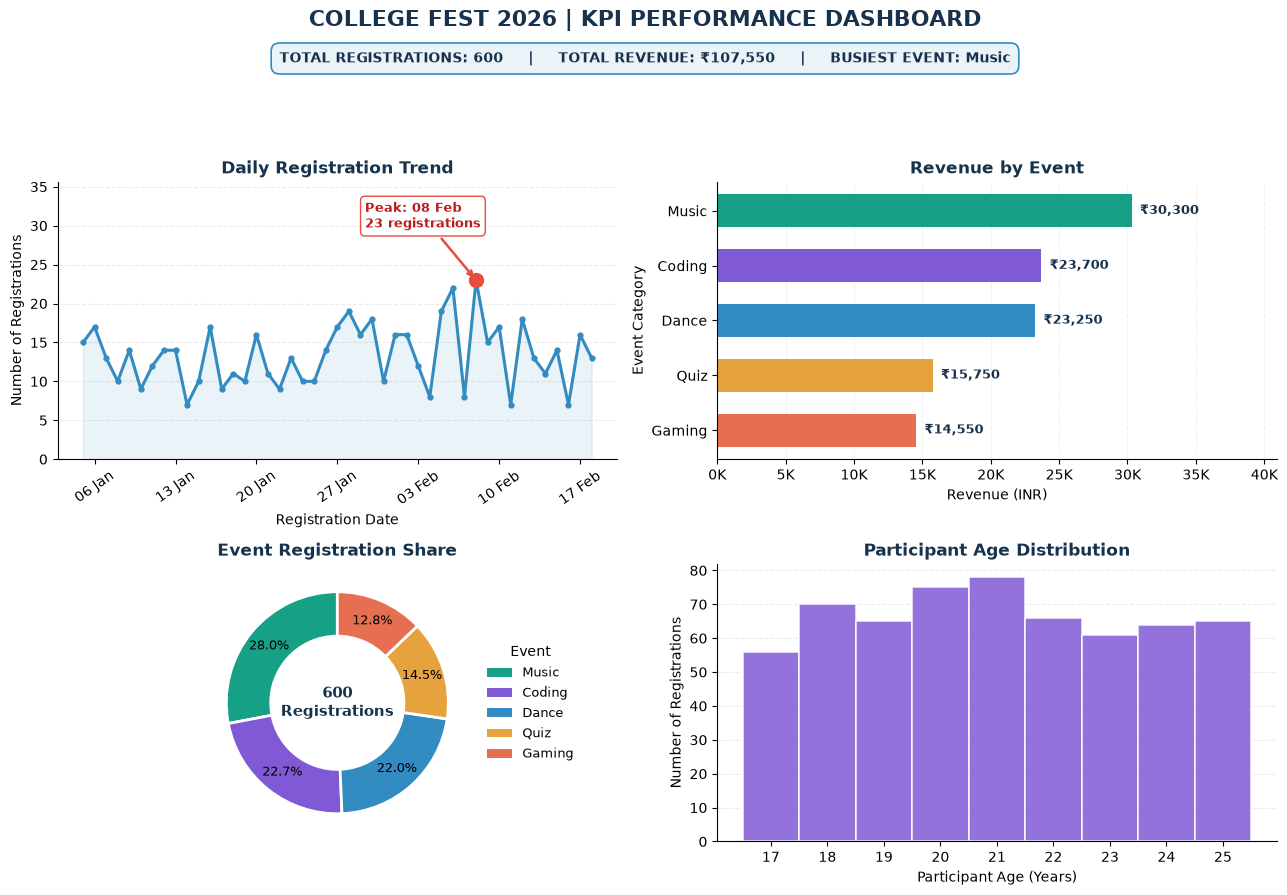

COLLEGE FEST 2026 - BUSINESS KPI REPORT
Total Registrations : 600
Total Revenue       : INR 107,550.00
Busiest Event       : Music
Peak Registration Day: 08 February 2026
Peak Day Registrations: 23

Event-wise Revenue:
event
Gaming    14550
Quiz      15750
Dance     23250
Coding    23700
Music     30300

SESSION 12 - TASK 3 COMPLETED SUCCESSFULLY!


In [3]:

# ============================================================
# MATPLOTLIB SESSION 12 - TASK 3
# COLLEGE FEST KPI DASHBOARD WITH BUSINESS ANNOTATIONS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Patch
from pathlib import Path

# ------------------------------------------------------------
# 1. LOAD AND VALIDATE THE DATA
# ------------------------------------------------------------

data_path = Path("fest_registrations.csv")

if not data_path.is_file():
    raise FileNotFoundError(
        "fest_registrations.csv not found."
    )

df = pd.read_csv(
    data_path,
    parse_dates=["reg_date"]
)

required = {
    "reg_date",
    "event",
    "ticket_type",
    "ticket_price_inr",
    "age"
}

missing = required - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

# ------------------------------------------------------------
# 2. CALCULATE BUSINESS KPIs
# ------------------------------------------------------------

daily_registrations = (
    df.groupby("reg_date")
    .size()
    .reindex(
        pd.date_range(
            df["reg_date"].min(),
            df["reg_date"].max(),
            freq="D"
        ),
        fill_value=0
    )
)

event_revenue = (
    df.groupby("event")["ticket_price_inr"]
    .sum()
    .sort_values(ascending=True)
)

event_counts = df["event"].value_counts()

total_registrations = len(df)
total_revenue = df["ticket_price_inr"].sum()

# Identify peak registration day dynamically
peak_date = daily_registrations.idxmax()
peak_count = int(daily_registrations.loc[peak_date])

# Identify busiest event
busiest_event = event_counts.idxmax()

# ------------------------------------------------------------
# 3. PROFESSIONAL DASHBOARD COLOR PALETTE
# ------------------------------------------------------------

NAVY = "#17324D"
BLUE = "#328CC1"
PURPLE = "#805AD5"

event_colors = {
    "Dance": "#328CC1",
    "Music": "#16A085",
    "Coding": "#805AD5",
    "Quiz": "#E6A23C",
    "Gaming": "#E76F51"
}

# ------------------------------------------------------------
# 4. CREATE 2 x 2 KPI DASHBOARD
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 9)
)

ax1, ax2 = axes[0]
ax3, ax4 = axes[1]

# ------------------------------------------------------------
# CHART 1 - DAILY REGISTRATION TREND
# ------------------------------------------------------------

ax1.plot(
    daily_registrations.index,
    daily_registrations.values,
    color=BLUE,
    linewidth=2.2,
    marker="o",
    markersize=3.5
)

ax1.fill_between(
    daily_registrations.index,
    daily_registrations.values,
    color=BLUE,
    alpha=0.10
)

# Highlight the peak registration day
ax1.scatter(
    peak_date,
    peak_count,
    color="#E74C3C",
    s=100,
    zorder=5
)

# Required peak-day arrow annotation
ax1.annotate(
    f"Peak: {peak_date:%d %b}\n{peak_count} registrations",
    xy=(peak_date, peak_count),
    xytext=(-80, 38),
    textcoords="offset points",
    fontsize=9,
    fontweight="bold",
    color="#B91C1C",
    arrowprops=dict(
        arrowstyle="->",
        color="#E74C3C",
        linewidth=1.8
    ),
    bbox=dict(
        boxstyle="round,pad=0.35",
        facecolor="white",
        edgecolor="#E74C3C"
    )
)

ax1.set_title(
    "Daily Registration Trend",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

ax1.set_xlabel("Registration Date")
ax1.set_ylabel("Number of Registrations")

ax1.xaxis.set_major_locator(
    mdates.WeekdayLocator(interval=1)
)

ax1.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

ax1.tick_params(axis="x", rotation=35)

ax1.set_ylim(
    0,
    max(daily_registrations.max() * 1.55, 1)
)

ax1.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

# ------------------------------------------------------------
# CHART 2 - EVENT-WISE REVENUE WITH RUPEE LABELS
# ------------------------------------------------------------

bar_colors = [
    event_colors[event]
    for event in event_revenue.index
]

bars = ax2.barh(
    event_revenue.index,
    event_revenue.values,
    color=bar_colors,
    height=0.6
)

# Required rupee values at the end of every bar
for bar in bars:
    revenue = bar.get_width()

    ax2.annotate(
        f"₹{revenue:,.0f}",
        xy=(
            revenue,
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(6, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
        fontweight="bold",
        color=NAVY
    )

ax2.set_xlim(
    0,
    event_revenue.max() * 1.35
)

ax2.set_title(
    "Revenue by Event",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

ax2.set_xlabel("Revenue (INR)")
ax2.set_ylabel("Event Category")

ax2.xaxis.set_major_formatter(
    FuncFormatter(
        lambda value, pos: f"{value / 1000:,.0f}K"
    )
)

ax2.grid(
    axis="x",
    linestyle="--",
    alpha=0.20
)

# ------------------------------------------------------------
# CHART 3 - EVENT REGISTRATION SHARE DONUT
# ------------------------------------------------------------

donut_colors = [
    event_colors[event]
    for event in event_counts.index
]

ax3.pie(
    event_counts.values,
    colors=donut_colors,
    startangle=90,
    autopct="%1.1f%%",
    pctdistance=0.80,
    wedgeprops=dict(
        width=0.4,
        edgecolor="white",
        linewidth=2
    ),
    textprops=dict(fontsize=9)
)

ax3.text(
    0, 0,
    f"{total_registrations:,}\nRegistrations",
    ha="center",
    va="center",
    fontsize=11,
    fontweight="bold",
    color=NAVY
)

ax3.set_title(
    "Event Registration Share",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

# Legend required for the multicolored donut
donut_legend = [
    Patch(
        facecolor=event_colors[event],
        label=event
    )
    for event in event_counts.index
]

ax3.legend(
    handles=donut_legend,
    title="Event",
    loc="center left",
    bbox_to_anchor=(1.0, 0.5),
    frameon=False,
    fontsize=9
)

ax3.set_aspect("equal")

# ------------------------------------------------------------
# CHART 4 - PARTICIPANT AGE DISTRIBUTION
# ------------------------------------------------------------

age_bins = np.arange(16.5, 26.5, 1)

ax4.hist(
    df["age"],
    bins=age_bins,
    color=PURPLE,
    edgecolor="white",
    linewidth=1.2,
    alpha=0.85
)

ax4.set_title(
    "Participant Age Distribution",
    fontsize=12,
    fontweight="bold",
    color=NAVY
)

ax4.set_xlabel("Participant Age (Years)")
ax4.set_ylabel("Number of Registrations")

ax4.set_xticks(range(17, 26))

ax4.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

# ------------------------------------------------------------
# 5. SUMMARY BOX - REQUIRED BUSINESS KPIs
# ------------------------------------------------------------

summary_text = (
    f"TOTAL REGISTRATIONS: {total_registrations:,}"
    f"     |     TOTAL REVENUE: ₹{total_revenue:,.0f}"
    f"     |     BUSIEST EVENT: {busiest_event}"
)

fig.text(
    0.5,
    0.935,
    summary_text,
    ha="center",
    va="center",
    fontsize=10,
    fontweight="bold",
    color=NAVY,
    bbox=dict(
        boxstyle="round,pad=0.6",
        facecolor="#EAF3F8",
        edgecolor=BLUE,
        linewidth=1.2
    )
)

# ------------------------------------------------------------
# 6. DASHBOARD TITLE AND FORMATTING
# ------------------------------------------------------------

fig.suptitle(
    "COLLEGE FEST 2026 | KPI PERFORMANCE DASHBOARD",
    fontsize=16,
    fontweight="bold",
    color=NAVY,
    y=0.99
)

for ax in [ax1, ax2, ax4]:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_axisbelow(True)

# Reserve space for title and summary box
fig.tight_layout(
    rect=[0, 0, 1, 0.88]
)

# Display final annotated dashboard
plt.show()

# ------------------------------------------------------------
# 7. PRINT BUSINESS PERFORMANCE SUMMARY
# ------------------------------------------------------------

print("=" * 55)
print("COLLEGE FEST 2026 - BUSINESS KPI REPORT")
print("=" * 55)

print(f"Total Registrations : {total_registrations:,}")
print(f"Total Revenue       : INR {total_revenue:,.2f}")
print(f"Busiest Event       : {busiest_event}")

print(
    f"Peak Registration Day: "
    f"{peak_date:%d %B %Y}"
)

print(f"Peak Day Registrations: {peak_count}")

print("\nEvent-wise Revenue:")
print(event_revenue.to_string())

print("\nSESSION 12 - TASK 3 COMPLETED SUCCESSFULLY!")


Task 4: Export the Final KPI Dashboard

In [4]:

# ============================================================
# MATPLOTLIB SESSION 12 - TASK 4
# EXPORT FINAL COLLEGE FEST KPI DASHBOARD
# ============================================================

from pathlib import Path
import pandas as pd

# 1. Define output files
png_file = Path("fest_kpi_panel.png")
pdf_file = Path("fest_kpi_report.pdf")

# 2. Export high-resolution PNG
# Save the annotated figure created in Task 3
fig.savefig(
    png_file,
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

# 3. Export professional PDF report
fig.savefig(
    pdf_file,
    bbox_inches="tight",
    facecolor="white"
)

# 4. Verify exported files
print("=" * 55)
print("COLLEGE FEST 2026 - DASHBOARD EXPORT REPORT")
print("=" * 55)

for file_path in [png_file, pdf_file]:

    if not file_path.is_file():
        raise FileNotFoundError(
            f"Export failed: {file_path.name}"
        )

    file_size_kb = file_path.stat().st_size / 1024

    print(f"\nFile Name : {file_path.name}")
    print(f"File Size : {file_size_kb:.2f} KB")
    print(f"File Path : {file_path.resolve()}")

# 5. Recalculate final KPIs from the actual dataset
report_df = pd.read_csv("fest_registrations.csv")

final_registrations = len(report_df)

final_revenue = report_df["ticket_price_inr"].sum()

final_busiest_event = (
    report_df["event"]
    .value_counts()
    .idxmax()
)

# 6. Print business performance summary
print("\n" + "=" * 55)
print("FINAL COLLEGE FEST KPI SUMMARY")
print("=" * 55)

print(f"Total Registrations : {final_registrations:,}")
print(f"Total Revenue       : INR {final_revenue:,.2f}")
print(f"Busiest Event       : {final_busiest_event}")

# 7. Validate expected registration count
assert final_registrations == 600, (
    "Registration count must be 600."
)

print("\nBoth dashboard exports completed successfully!")

# 8. Display the chart AFTER saving
plt.show()


COLLEGE FEST 2026 - DASHBOARD EXPORT REPORT

File Name : fest_kpi_panel.png
File Size : 294.56 KB
File Path : D:\sql+power bi\assmt\recharge_export.ipynb\fest_kpi_panel.png

File Name : fest_kpi_report.pdf
File Size : 41.34 KB
File Path : D:\sql+power bi\assmt\recharge_export.ipynb\fest_kpi_report.pdf

FINAL COLLEGE FEST KPI SUMMARY
Total Registrations : 600
Total Revenue       : INR 107,550.00
Busiest Event       : Music

Both dashboard exports completed successfully!
